# Efficient Frontier

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots expected return against volatility for thousands of possible portfolios, traces the efficient frontier (the best return for each level of risk) and adds the capital market line from the risk-free rate through the tangency (maximum-Sharpe) portfolio. It is the picture behind modern portfolio theory: diversification moves portfolios up and to the left of the individual assets.

## When to use

- Explain diversification and the risk-return trade-off
- Compare a proposed allocation with what is achievable from the same assets
- Teach mean-variance optimisation, the minimum-variance and maximum-Sharpe portfolios

## Avoid when

- Presenting the optimised weights as precise (they are very sensitive to expected-return estimates)
- Return estimates are just historical averages over a short period (the frontier will be overfitted)

## Alternatives

- Risk-return scatter of actual funds
- Risk contribution chart for one chosen portfolio

## Design tips

- Color the random portfolios by Sharpe ratio with a one-hue sequential scale
- Mark the minimum-variance and tangency portfolios and label the individual assets
- State the assumptions (expected returns, covariance, no short sales, risk-free rate)

## Example

Five simulated asset classes with assumed expected returns, volatilities and correlations; 6,000 random long-only portfolios; 3% risk-free rate. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.optimize import minimize
from matplotlib.ticker import PercentFormatter

### Data

In [2]:
assets = ["US equities", "Intl equities", "EM equities", "Gov. bonds", "Gold"]
mu = pd.Series([0.075, 0.07, 0.085, 0.035, 0.045], index=assets)    # expected annual return
vol = np.array([0.16, 0.17, 0.23, 0.06, 0.15])
corr = np.array([[1.0, 0.8, 0.7, -0.2, 0.05],
                 [0.8, 1.0, 0.75, -0.15, 0.1],
                 [0.7, 0.75, 1.0, -0.1, 0.2],
                 [-0.2, -0.15, -0.1, 1.0, 0.3],
                 [0.05, 0.1, 0.2, 0.3, 1.0]])
cov = pd.DataFrame(np.outer(vol, vol) * corr, index=assets, columns=assets)
rf = 0.03
mu

US equities      0.075
Intl equities    0.070
EM equities      0.085
Gov. bonds       0.035
Gold             0.045
dtype: float64

### Plot

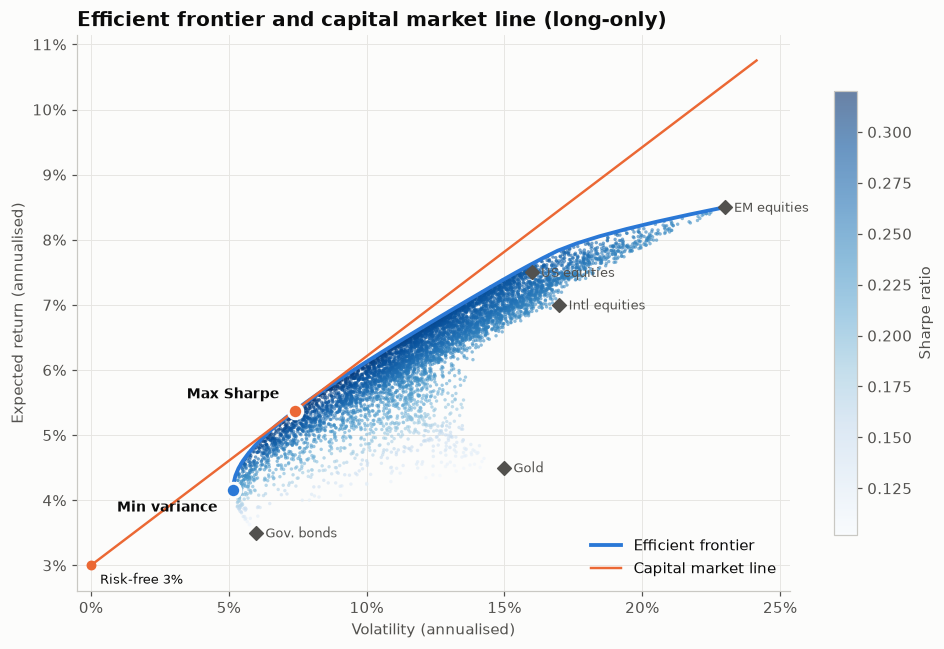

In [3]:
rng = np.random.default_rng(1)
k = len(mu)
m, S = mu.values, cov.values
W = rng.dirichlet(np.full(k, 0.6), 6000)
p_ret, p_vol = W @ m, np.sqrt(np.einsum("ij,jk,ik->i", W, S, W))

def min_vol(target):
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w: w @ m - target}]
    res = minimize(lambda w: w @ S @ w, np.full(k, 1 / k), bounds=[(0, 1)] * k, constraints=cons)
    return np.sqrt(res.fun) if res.success else np.nan

cons1 = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
w_mv = minimize(lambda w: w @ S @ w, np.full(k, 1 / k), bounds=[(0, 1)] * k, constraints=cons1).x
w_tan = minimize(lambda w: -(w @ m - rf) / np.sqrt(w @ S @ w), np.full(k, 1 / k),
                 bounds=[(0, 1)] * k, constraints=cons1).x
targets = np.linspace(w_mv @ m, m.max(), 40)
front = np.array([min_vol(t) for t in targets])
tan_ret, tan_vol = w_tan @ m, np.sqrt(w_tan @ S @ w_tan)
mv_ret, mv_vol = w_mv @ m, np.sqrt(w_mv @ S @ w_mv)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(p_vol, p_ret, c=(p_ret - rf) / p_vol, cmap=SEQ_CMAP, s=5, alpha=0.6, linewidths=0)
fig.colorbar(sc, ax=ax, label="Sharpe ratio", shrink=0.8)
ax.plot(front, targets, color=PALETTE[0], linewidth=2.5, label="Efficient frontier")
xs = np.linspace(0, max(np.sqrt(np.diag(S)).max(), p_vol.max()) * 1.05, 50)
ax.plot(xs, rf + (tan_ret - rf) / tan_vol * xs, color=PALETTE[1], linewidth=1.6, label="Capital market line")
for x, y, lab in [(tan_vol, tan_ret, "Max Sharpe"), (mv_vol, mv_ret, "Min variance")]:
    ax.scatter(x, y, s=90, color=PALETTE[1] if lab == "Max Sharpe" else PALETTE[0], zorder=4,
               edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(lab, (x, y), xytext=(-10, 8) if lab == "Max Sharpe" else (-10, -14), textcoords="offset points",
                ha="right", fontsize=9, weight="bold")
for name, x, y in zip(mu.index, np.sqrt(np.diag(S)), m):
    ax.scatter(x, y, s=40, marker="D", color="#52514e", zorder=4)
    ax.annotate(name, (x, y), xytext=(6, -3), textcoords="offset points", fontsize=8.5, color="#52514e")
ax.scatter(0, rf, s=30, color=PALETTE[1], zorder=4)
ax.annotate(f"Risk-free {rf:.0%}", (0, rf), xytext=(6, -12), textcoords="offset points", fontsize=8.5)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(left=-0.005)
ax.set_xlabel("Volatility (annualised)")
ax.set_ylabel("Expected return (annualised)")
ax.set_title("Efficient frontier and capital market line (long-only)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

Each small dot is one random portfolio (darker = higher Sharpe ratio). The blue curve is the efficient frontier: no portfolio does better at the same risk. The orange line from the risk-free rate touches the frontier at the tangency portfolio, the mix with the best return per unit of risk.

## Try it with real data

**Source:** plotly.express.data.stocks() — 6 tech stocks, mean and covariance of weekly returns 2018–2019 (annualised)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
weekly = stocks.pct_change().dropna()
mu = weekly.mean() * 52
cov = weekly.cov() * 52
rf = 0.02
mu

GOOG    0.124541
AAPL    0.295419
AMZN    0.241444
FB      0.096104
NFLX    0.305886
MSFT    0.309841
dtype: float64

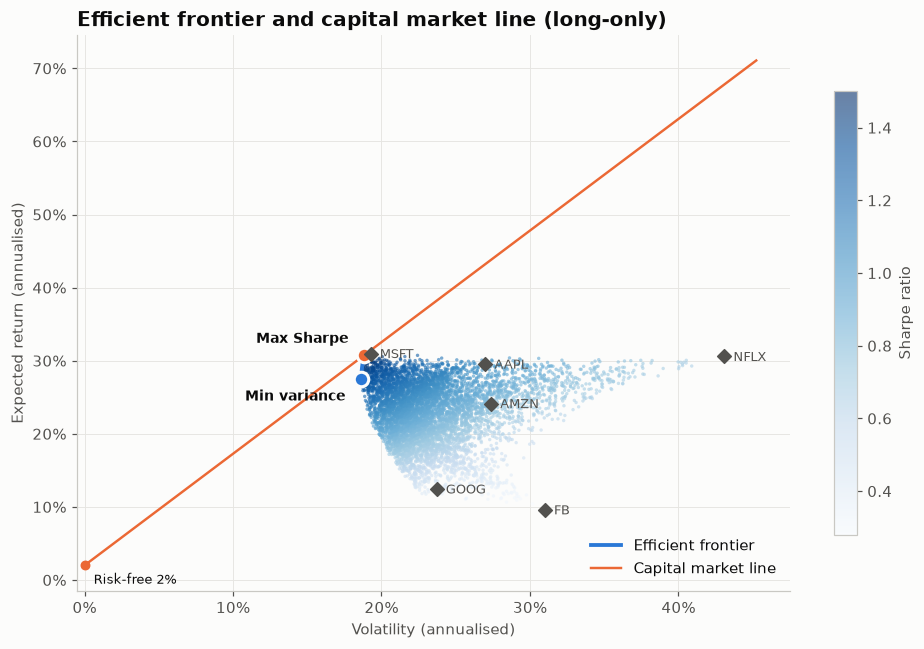

In [5]:
rng = np.random.default_rng(1)
k = len(mu)
m, S = mu.values, cov.values
W = rng.dirichlet(np.full(k, 0.6), 6000)
p_ret, p_vol = W @ m, np.sqrt(np.einsum("ij,jk,ik->i", W, S, W))

def min_vol(target):
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w: w @ m - target}]
    res = minimize(lambda w: w @ S @ w, np.full(k, 1 / k), bounds=[(0, 1)] * k, constraints=cons)
    return np.sqrt(res.fun) if res.success else np.nan

cons1 = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
w_mv = minimize(lambda w: w @ S @ w, np.full(k, 1 / k), bounds=[(0, 1)] * k, constraints=cons1).x
w_tan = minimize(lambda w: -(w @ m - rf) / np.sqrt(w @ S @ w), np.full(k, 1 / k),
                 bounds=[(0, 1)] * k, constraints=cons1).x
targets = np.linspace(w_mv @ m, m.max(), 40)
front = np.array([min_vol(t) for t in targets])
tan_ret, tan_vol = w_tan @ m, np.sqrt(w_tan @ S @ w_tan)
mv_ret, mv_vol = w_mv @ m, np.sqrt(w_mv @ S @ w_mv)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(p_vol, p_ret, c=(p_ret - rf) / p_vol, cmap=SEQ_CMAP, s=5, alpha=0.6, linewidths=0)
fig.colorbar(sc, ax=ax, label="Sharpe ratio", shrink=0.8)
ax.plot(front, targets, color=PALETTE[0], linewidth=2.5, label="Efficient frontier")
xs = np.linspace(0, max(np.sqrt(np.diag(S)).max(), p_vol.max()) * 1.05, 50)
ax.plot(xs, rf + (tan_ret - rf) / tan_vol * xs, color=PALETTE[1], linewidth=1.6, label="Capital market line")
for x, y, lab in [(tan_vol, tan_ret, "Max Sharpe"), (mv_vol, mv_ret, "Min variance")]:
    ax.scatter(x, y, s=90, color=PALETTE[1] if lab == "Max Sharpe" else PALETTE[0], zorder=4,
               edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(lab, (x, y), xytext=(-10, 8) if lab == "Max Sharpe" else (-10, -14), textcoords="offset points",
                ha="right", fontsize=9, weight="bold")
for name, x, y in zip(mu.index, np.sqrt(np.diag(S)), m):
    ax.scatter(x, y, s=40, marker="D", color="#52514e", zorder=4)
    ax.annotate(name, (x, y), xytext=(6, -3), textcoords="offset points", fontsize=8.5, color="#52514e")
ax.scatter(0, rf, s=30, color=PALETTE[1], zorder=4)
ax.annotate(f"Risk-free {rf:.0%}", (0, rf), xytext=(6, -12), textcoords="offset points", fontsize=8.5)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(left=-0.005)
ax.set_xlabel("Volatility (annualised)")
ax.set_ylabel("Expected return (annualised)")
ax.set_title("Efficient frontier and capital market line (long-only)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

---
Standalone script: [`efficient_frontier.py`](efficient_frontier.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)